# 15 · Uncertainty analysis

## Purpose

Flag low-margin probabilities for additional review and assess risk discrimination on progressively more confident subsets.

## Method

Create a decision-study holdout from the training partition, calibrate only on its separate calibration subset, and summarize probability margin, coverage, error, and ROC-AUC among retained confident predictions.

## Interpretation

Use the displayed tables, figures, and saved metrics produced by this run. Do not fill this section with assumed outcomes. For every result, distinguish observed evidence from interpretation.

## Limitations

Margin-based flags are heuristic. They are not a conformal prediction set and provide no finite-sample coverage guarantee.

## References

For this study, uncertainty flags are operational review cues; conformal methods are not enabled.


In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd().resolve()
while not (ROOT / 'returnwise').is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from IPython.display import display
from returnwise.research_state import load_state, save_state
state = load_state()
print('Project:', ROOT)
print('Notebook:', '15 · Uncertainty analysis')


Project: C:\Users\Lenovo\Documents\Who is back
Notebook: 15 · Uncertainty analysis


,method,roc_auc,pr_auc,brier_score,log_loss,expected_calibration_error
0,uncalibrated,0.592534,0.557368,0.243004,0.678976,0.016340
1,sigmoid,0.592534,0.557368,0.242691,0.678314,0.005051
2,isotonic,0.591964,0.550961,0.242884,0.678754,0.003654
3,beta,0.592534,0.557368,0.242690,0.678313,0.005397


Selected calibration method used for the decision-study holdout: beta
{'minimum_confidence': 0.5, 'coverage': 1.0, 'rows_retained': 32000, 'roc_auc_retained': 0.5925338143857843}
{'minimum_confidence': 0.6, 'coverage': 0.2449375, 'rows_retained': 7838, 'roc_auc_retained': 0.6375764782083905}
{'minimum_confidence': 0.7, 'coverage': 0.014, 'rows_retained': 448, 'roc_auc_retained': 0.5670272524345672}
{'minimum_confidence': 0.8, 'coverage': 0.0, 'rows_retained': 0, 'roc_auc_retained': nan}
{'minimum_confidence': 0.9, 'coverage': 0.0, 'rows_retained': 0, 'roc_auc_retained': nan}


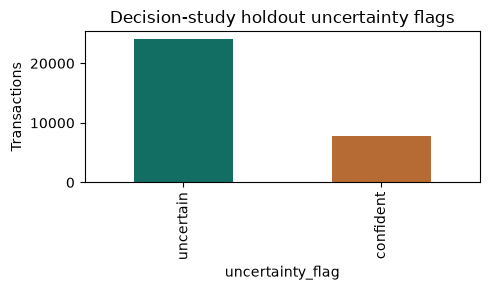

In [2]:
from returnwise.experiments import make_holdout_predictions
from returnwise.research_state import load_state, save_state
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score

state = load_state()
decision_model, decision_calibrators, decision_predictions, decision_metrics = make_holdout_predictions(
    state['X_train'], state['y_train'], state['selected_model'], mode=state.get('experiment_mode', 'quick'), seed=104,
    parameters=(state.get('tuning_result') or {}).get('pipeline_parameters') if (state.get('tuning_result') or {}).get('model') == state['selected_model'] else None,
)
calibrator_name = state['selected_calibrator']
if calibrator_name not in decision_predictions.columns.str.replace('probability_', '').tolist():
    calibrator_name = 'uncalibrated'
calibrated_column = f'probability_{calibrator_name}'
decision_predictions.attrs['selected_calibrator'] = calibrator_name
p = decision_predictions[calibrated_column].to_numpy()
y = decision_predictions['y_true'].to_numpy()
decision_predictions['probability_margin'] = np.abs(p - 0.5) * 2
decision_predictions['confidence'] = np.maximum(p, 1 - p)
decision_predictions['uncertainty_flag'] = decision_predictions['confidence'] < 0.60
display(decision_metrics)
print('Selected calibration method used for the decision-study holdout:', calibrator_name)
for min_confidence in [0.50, 0.60, 0.70, 0.80, 0.90]:
    mask = decision_predictions['confidence'] >= min_confidence
    score = roc_auc_score(y[mask], p[mask]) if mask.sum() > 1 and len(np.unique(y[mask])) == 2 else float('nan')
    print({'minimum_confidence': min_confidence, 'coverage': float(mask.mean()), 'rows_retained': int(mask.sum()), 'roc_auc_retained': score})
counts = decision_predictions['uncertainty_flag'].value_counts().rename(index={False: 'confident', True: 'uncertain'})
ax = counts.plot.bar(figsize=(5, 3), color=['#126E63', '#B56B33'], title='Decision-study holdout uncertainty flags')
ax.set_ylabel('Transactions')
plt.tight_layout()
plt.show()
state.update({'decision_model': decision_model, 'decision_calibrators': decision_calibrators,
              'decision_predictions': decision_predictions, 'decision_metrics': decision_metrics,
              'decision_calibrator_name': calibrator_name})
from returnwise.experiments import log_experiment
log_experiment('Uncertainty analysis', None,
               {'calibration_metrics': decision_metrics.to_dict(orient='records'),
                'uncertain_rows': int(decision_predictions['uncertainty_flag'].sum())},
               {'model': state['selected_model'], 'calibrator': calibrator_name})
save_state(state)
